# Lab 9- Deep Learning Model

This lab is meant to get you started in using Keras to design Deep Neural Networks. The goal here is to simply repeat your previous lab, but with DNNs.

Lecture 21 is your template: it reads the same data, builds, compiles and trains a network, plots its learning curves, and makes a ROC curve. Copy its cells and change the numbers.

Let's start with reading the data, like before. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, as in Lab 8. You will need both in Exercise 2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]

df = pd.read_csv(filename, dtype='float64', names=VarNames)

Now let's define the samples. DNNs take long to train, so to start we use only the first 500,000 of the 5 million events for training. Once you get everything working, make the final version of your plots with more.

We keep **three** samples, because they do different jobs:

* **training**: what `fit` learns from;
* **validation**: what you watch while you work (pass it to `fit` as `validation_data`), and what you use to choose between models;
* **test**: used only at the end, to report the performance of the models you chose.

Keras works on NumPy arrays, so after doing all of the nice manipulation that pandas enables, we convert the DataFrames to NumPy arrays.

In [2]:
N_Train=500000
N_Val=50000
N_Test=50000

Train_Sample=df[:N_Train]
Val_Sample=df[N_Train:N_Train+N_Val]
Test_Sample=df[N_Train+N_Val:N_Train+N_Val+N_Test]

X_Train=np.array(Train_Sample[VarNames[1:]])
y_Train=np.array(Train_Sample["signal"])

X_Val=np.array(Val_Sample[VarNames[1:]])
y_Val=np.array(Val_Sample["signal"])

X_Test=np.array(Test_Sample[VarNames[1:]])
y_Test=np.array(Test_Sample["signal"])

print(X_Train.shape, X_Val.shape, X_Test.shape)

(500000, 18) (50000, 18) (50000, 18)


## Exercise 1

You will need to create several models and make sure they are properly trained. Write a function that takes this history and plots the values versus epoch. For every model that you train in the remainder of this lab, assess:

* Has your model's performance plateaued? If not train for more epochs. 
* Compare the performance on the training and validation samples. Are you over training?

In [3]:
def plot_history(history, title="Model Learn Curves"):
    hist = history.history
    epochs = range(1, len(hist["loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, hist["loss"], "b-", label="Train loss")
    if "val_loss" in hist:
        ax1.plot(epochs, hist["val_loss"], "r--", label="Valid Loss")
    ax1.set_title(title + "- Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)
    acc_key = (
        "accuracy"
        if "accuracy" in hist
        else ("acc" if "acc" in hist else None)
    )
    if acc_key:
        ax2.plot(epochs, hist[acc_key], "b-", label="Training accuracy")
        val_acc_key=f"val_{acc_key}"
        if val_acc_key in hist:
            ax2.plot(epochs, hist[val_acc_key], "r--", label="Valid accuracy")
        ax2.set_title(title + "- Accuracy")
        ax2.set_xlabel("Epoch")
        ax2.set_ylabel("Accuracy")
        ax2.legend()
        ax2.grid(True)
    plt.tight_layout()
    plt.show()

In [20]:
%pip install tensorflow

  Using cached tensorflow-2.22.0rc0-cp314-cp314-manylinux_2_27_x86_64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.2-cp314-cp314-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (7.6 kB)
  Using cached grpcio-1.85.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (3.8 kB)
  Using cached keras_nightly-

## Exercise 2

Following the original paper (see Lab 7), make a comparison of the performance (using ROC curves and AUC) between models trained with the raw quantities (`RawNames`), the derived features (`FeatureNames`), and both. Note that the first layer's input shape changes with the number of inputs.

In [4]:
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
def build_and_train(X_tr, y_tr, X_v, y_v, epochs=20, batch_size=256):
    model = Sequential([
        Dense(64, activation="relu", input_shape=(X_tr.shape[1],)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_v, y_v),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1
    )
    return model, history
    

I0000 00:00:1794627218.249973     612 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794627218.833153     612 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794627222.001007     612 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/home/rhpat/Data-3402/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794627233.114084     612 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Epoch 1/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7823 - loss: 0.4650 - val_accuracy: 0.7873 - val_loss: 0.4539
Epoch 2/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7914 - loss: 0.4489 - val_accuracy: 0.7906 - val_loss: 0.4463
Epoch 3/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7949 - loss: 0.4425 - val_accuracy: 0.7935 - val_loss: 0.4428
Epoch 4/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7967 - loss: 0.4391 - val_accuracy: 0.7945 - val_loss: 0.4414
Epoch 5/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7980 - loss: 0.4372 - val_accuracy: 0.7950 - val_loss: 0.4405
Epoch 6/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7985 - loss: 0.4360 - val_accuracy: 0.7955 - val_loss: 0.4393
Epoch 7/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7991 - loss: 0.4350 - val_accuracy: 0.7954 - val_loss: 0.4388
Epoch 8/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7996 - loss: 0.4342 - 

<Figure size 800x600 with 0 Axes>

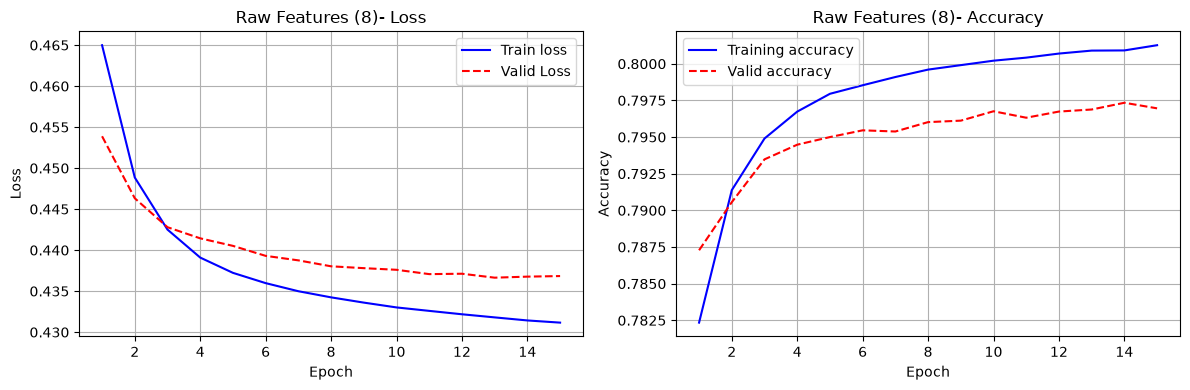

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Epoch 1/15


/home/rhpat/Data-3402/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7859 - loss: 0.4592 - val_accuracy: 0.7885 - val_loss: 0.4526
Epoch 2/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7909 - loss: 0.4492 - val_accuracy: 0.7897 - val_loss: 0.4506
Epoch 3/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7919 - loss: 0.4475 - val_accuracy: 0.7904 - val_loss: 0.4498
Epoch 4/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7924 - loss: 0.4463 - val_accuracy: 0.7913 - val_loss: 0.4485
Epoch 5/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7927 - loss: 0.4454 - val_accuracy: 0.7924 - val_loss: 0.4474
Epoch 6/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7930 - loss: 0.4447 - val_accuracy: 0.7919 - val_loss: 0.4470
Epoch 7/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7935 - loss: 0.4441 - val_accuracy: 0.7920 - val_loss: 0.4465
Epoch 8/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7936 - loss: 0.4436 - val_accurac

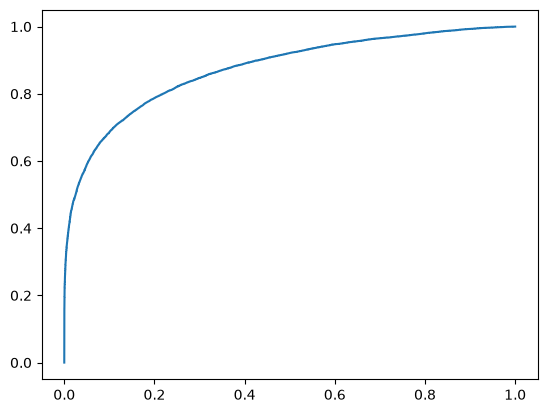

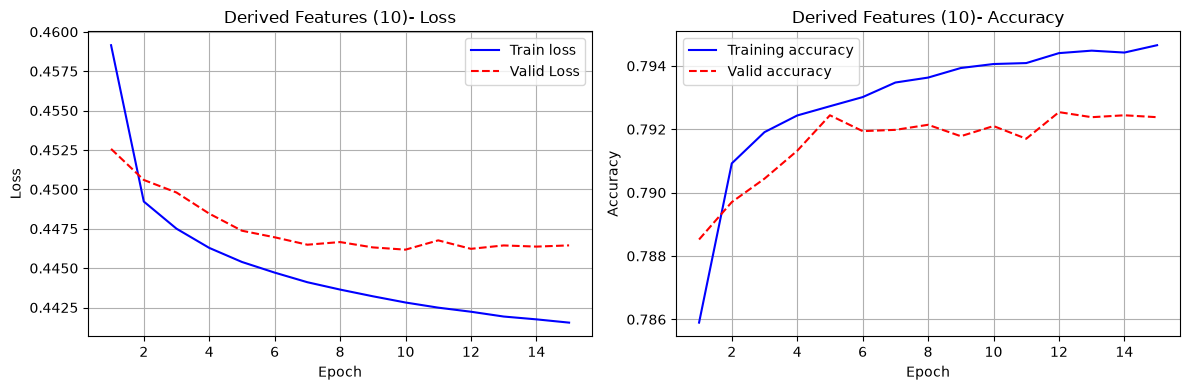

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Epoch 1/15


/home/rhpat/Data-3402/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7935 - loss: 0.4453 - val_accuracy: 0.7957 - val_loss: 0.4397
Epoch 2/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7990 - loss: 0.4345 - val_accuracy: 0.7973 - val_loss: 0.4360
Epoch 3/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8004 - loss: 0.4323 - val_accuracy: 0.7982 - val_loss: 0.4341
Epoch 4/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8010 - loss: 0.4309 - val_accuracy: 0.7978 - val_loss: 0.4332
Epoch 5/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8018 - loss: 0.4298 - val_accuracy: 0.7977 - val_loss: 0.4326
Epoch 6/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8023 - loss: 0.4290 - val_accuracy: 0.7979 - val_loss: 0.4325
Epoch 7/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8024 - loss: 0.4284 - val_accuracy: 0.7984 - val_loss: 0.4325
Epoch 8/15
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8027 - loss: 0.4280 - val_accurac

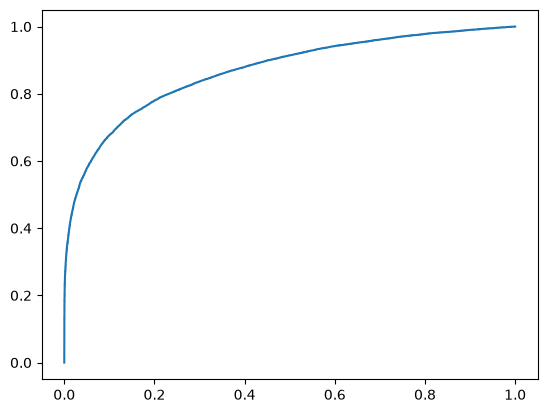

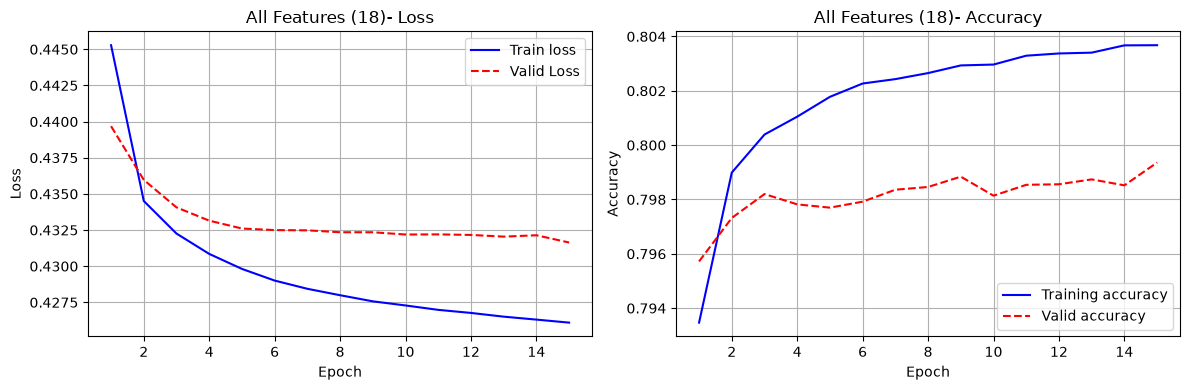

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


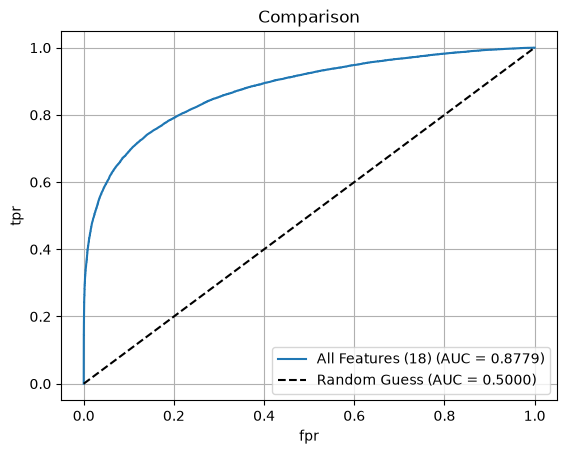

In [5]:
feature_sets = {
    "Raw Features (8)": RawNames,
    "Derived Features (10)": FeatureNames,
    "All Features (18)": VarNames[1:]
}
plt.figure(figsize=(8,6))
for label, cols in feature_sets.items():
    X_tr = np.array(Train_Sample[cols])
    X_v = np.array(Val_Sample[cols])
    X_te = np.array(Test_Sample[cols])

    model, history = build_and_train(X_tr, y_Train, X_v, y_Val, epochs=15)
    plot_history(history, title=label)

    y_pred = model.predict(X_te).ravel()
    fpr, tpr, _ = roc_curve(y_Test, y_pred)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{label} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.5000)")
plt.xlabel("fpr")
plt.ylabel("tpr")
plt.title("Comparison")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


## Exercise 3

Design and implement at least 3 different DNN models. Train them and compare performance. You may try different architectures, loss functions, and optimizers to see if there is an effect.

/home/rhpat/Data-3402/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Baseline_Shallow Training
Epoch 1/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7918 - loss: 0.4468 - val_accuracy: 0.7955 - val_loss: 0.4394
Epoch 2/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7990 - loss: 0.4349 - val_accuracy: 0.7967 - val_loss: 0.4367
Epoch 3/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8000 - loss: 0.4331 - val_accuracy: 0.7965 - val_loss: 0.4355
Epoch 4/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8003 - loss: 0.4319 - val_accuracy: 0.7971 - val_loss: 0.4349
Epoch 5/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8008 - loss: 0.4310 - val_accuracy: 0.7976 - val_loss: 0.4342
Epoch 6/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8012 - loss: 0.4303 - val_accuracy: 0.7978 - val_loss: 0.4336
Epoch 7/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8017 - loss: 0.4296 - val_accuracy: 0.7984 - val_loss: 0.4333
Epoch 8/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy

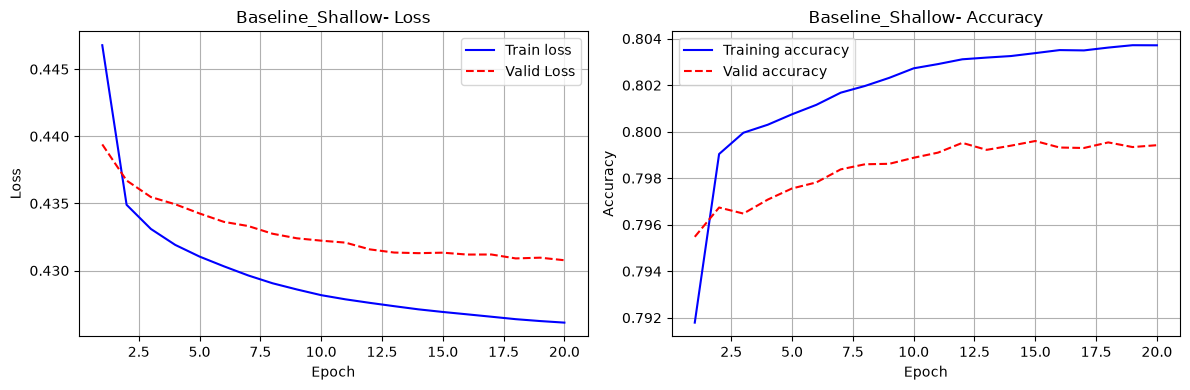

Deep_Model Training
Epoch 1/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7945 - loss: 0.4430 - val_accuracy: 0.7971 - val_loss: 0.4374
Epoch 2/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7997 - loss: 0.4339 - val_accuracy: 0.7971 - val_loss: 0.4359
Epoch 3/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8006 - loss: 0.4318 - val_accuracy: 0.7975 - val_loss: 0.4345
Epoch 4/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8017 - loss: 0.4302 - val_accuracy: 0.7981 - val_loss: 0.4331
Epoch 5/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8025 - loss: 0.4290 - val_accuracy: 0.7985 - val_loss: 0.4325
Epoch 6/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8027 - loss: 0.4281 - val_accuracy: 0.7982 - val_loss: 0.4321
Epoch 7/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8030 - loss: 0.4274 - val_accuracy: 0.7982 - val_loss: 0.4323
Epoch 8/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.80

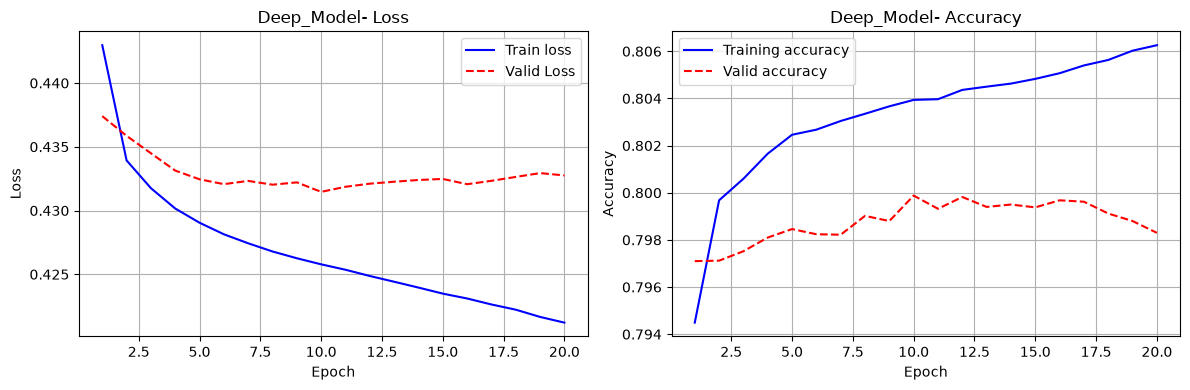

Tanh_Model Training
Epoch 1/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7949 - loss: 0.4430 - val_accuracy: 0.7966 - val_loss: 0.4369
Epoch 2/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7991 - loss: 0.4349 - val_accuracy: 0.7971 - val_loss: 0.4358
Epoch 3/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8000 - loss: 0.4331 - val_accuracy: 0.7976 - val_loss: 0.4342
Epoch 4/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8006 - loss: 0.4319 - val_accuracy: 0.7976 - val_loss: 0.4333
Epoch 5/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8009 - loss: 0.4310 - val_accuracy: 0.7982 - val_loss: 0.4327
Epoch 6/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8015 - loss: 0.4302 - val_accuracy: 0.7983 - val_loss: 0.4323
Epoch 7/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8020 - loss: 0.4295 - val_accuracy: 0.7983 - val_loss: 0.4321
Epoch 8/20
1954/1954 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.80

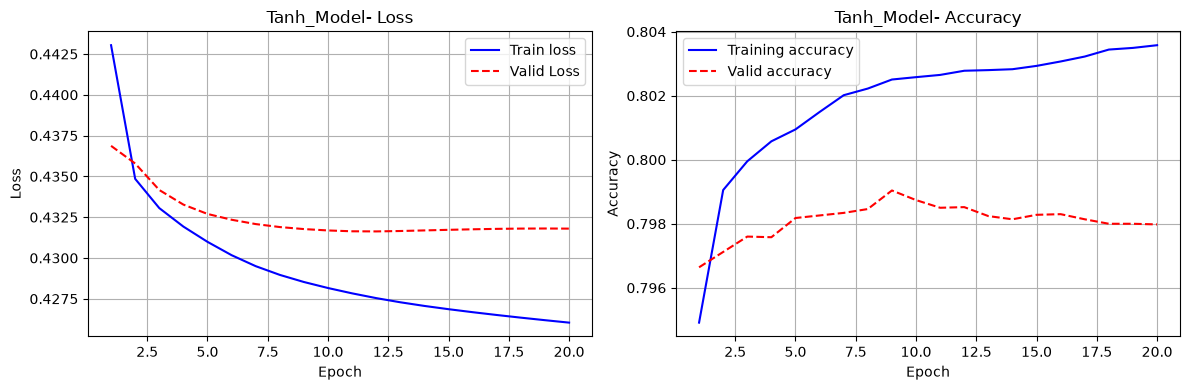

In [6]:

def get_models(input_dim):
    m1 = Sequential([
        Dense(64, activation="relu", input_shape=(input_dim,)),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ], name="Baseline_Shallow")
    m1.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    m2 = Sequential([
        Dense(128, activation="relu", input_shape=(input_dim,)),
        Dense(128, activation="relu"),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ], name="Deep_Model")
    m2.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    m3 = Sequential([
        Dense(100, activation="tanh", input_shape=(input_dim,)),
        Dense(50, activation="tanh"),
        Dense(25, activation="tanh"),
        Dense(1, activation="sigmoid")
    ], name="Tanh_Model")
    m3.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return [m1, m2, m3]

models = get_models(X_Train.shape[1])
histories = {}

for model in models:
    print(f"{model.name} Training")
    hist = model.fit(
        X_Train, y_Train,
        validation_data=(X_Val, y_Val),
        epochs=20,
        batch_size=256,
        verbose=1
    )
    histories[model.name] = hist
    plot_history(hist, title=model.name)

## Exercise 4

Repeat Exercise 4 from Lab 8 (parts b and c), adding your best performing DNN as one of the models. Choose your best DNN using the validation sample, then compare on the test sample.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

In [10]:
def evaluate_classifier(clf, X_train, y_train, X_test, y_test):
    print("Training", clf.__class__.__name__)
    clf.fit(X_train, y_train)
    if hasattr(clf, "predict_proba"):
        scores = clf.predict_proba(X_test)[:, 1]
    else:
        scores =clf.decision_function(X_test)
    fpr, tpr, thresholds = roc_curve(y_test, scores)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, thresholds, scores, roc_auc

model_lr = LogisticRegression(max_iter=1000)
model_rf = RandomForestClassifier(n_estimators=50, max_depth=10, n_jobs=-1, random_state=38)
model_nb = GaussianNB()
fpr_lr, tpr_lr, thresh_lr, scores_lr, auc_lr = evaluate_classifier(model_lr, X_Train, y_Train, X_Test, y_Test)
fpr_rf, tpr_rf, thresh_rf, scores_rf, auc_rf = evaluate_classifier(model_rf, X_Train, y_Train, X_Test, y_Test)
fpr_nb, tpr_nb, thresh_nb, scores_nb, auc_nb = evaluate_classifier(model_nb, X_Train, y_Train, X_Test, y_Test)

scores_lda = Fisher.decision_function(X_Test)
fpr_lda, tpr_lda, _ = roc_curve(y_Test, scores_lda)
auc_lda = auc(fpr_lda, tpr_lda)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, color="red", label=f" Logistic Regression (AUC = {auc_lr:.4f})")
plt.plot(fpr_rf, tpr_rf, color="blue", label=f"Random Forest (AUC = {auc_rf:.4f})")
plt.plot(fpr_nb, tpr_nb, color="green", label=f"Gaussian (AUC = {auc_nb:.4f})")
plt.plot(fpr_lda, tpr_lda, color="orange", linestyle="--", label=f"LDA (AUC = {auc_lda:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle=":")

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Three Classifiers")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

Training LogisticRegression
Training RandomForestClassifier
Training GaussianNB


NameError: name 'Fisher' is not defined

Scenario 1
Max Significance: 1.79
Threshold Cut: 0.7705
Scenario 2
Max Significance: 5.67
Threshold Cut: 0.7705
Scenario 3
Max Significance: 17.92
Threshold Cut: 0.7705
Scenario 4
Max Significance: 56.66
Threshold Cut: 0.7705


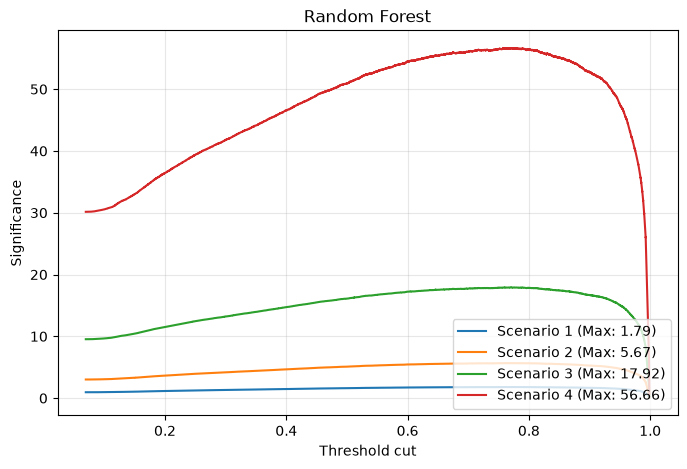

In [11]:
scenarios = {
    "Scenario 1": (10, 100),
    "Scenario 2": (100, 1000),
    "Scenario 3": (1000, 10000),
    "Scenario 4": (10000, 100000),
}
def calc_and_plot_signif(y_true, y_scores, model_name):
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    answers = {}
    plt.figure(figsize=(8, 5))
    for name, (NS, NB) in scenarios.items():
        S = tpr * NS
        B = fpr * NB
        significance = np.divide(S, np.sqrt(S + B), out=np.zeros_like(S), where=(S + B) > 0)
        
        max_idx = np.argmax(significance)
        max_sig = significance[max_idx]
        best_threshold = thresholds[max_idx]
        answers[name] = (max_sig, best_threshold)
        plt.plot(thresholds, significance, label=f"{name} (Max: {max_sig:.2f})")
        print(name)
        print(f"Max Significance: {max_sig:.2f}")
        print(f"Threshold Cut: {best_threshold:.4f}")
    plt.xlabel("Threshold cut")
    plt.ylabel("Significance")
    plt.title("Random Forest")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()
    return answers

significance_answers = calc_and_plot_signif(y_Test, scores_rf, RandomForestClassifier)

In [ ]:
# In this lab, I used LLMS to check the exercises if they were done correctly.
# I had to install the tensorflow to help get exercise 2 and 3 done.